## Phase 3.1 - Target Variable Analysis

Objective

Understand the distribution of customers who churned and those who remained.

Why do we analyze the target variable first?
1. To understand the distribution of the classes.
2. To identify whether the dataset is balanced or imbalanced.
3. To understand whether accuracy alone will be a reliable evaluation metric.
4. To gain an initial understanding of the business problem.

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Better looking plots
# plt.style.use("ggplot")

# Display all columns
# pd.set_option("display.max_columns", None)

In [3]:
df = pd.read_excel("../data/raw/Telco_customer_churn.xlsx")

Count the Customers Who Churned

In [4]:
df["Churn Label"].value_counts(normalize=True)*100

Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

Visualize

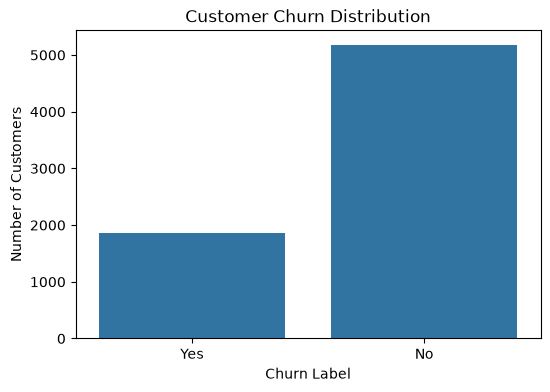

In [5]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="Churn Label"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Label")
plt.ylabel("Number of Customers")

plt.show()

Identify Numerical Features

In [6]:
numerical_cols = df.select_dtypes(include=["float64","int64"]).columns

numerical_cols

Index(['Count', 'Zip Code', 'Latitude', 'Longitude', 'Tenure Months',
       'Monthly Charges', 'Churn Value', 'Churn Score', 'CLTV'],
      dtype='str')

In [7]:
selected_num_cols = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "CLTV"
]

# We focus on this four features

Analyze One Feature at a Time

1. Tenure Months

In [8]:
df["Tenure Months"].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: Tenure Months, dtype: float64

Histogram

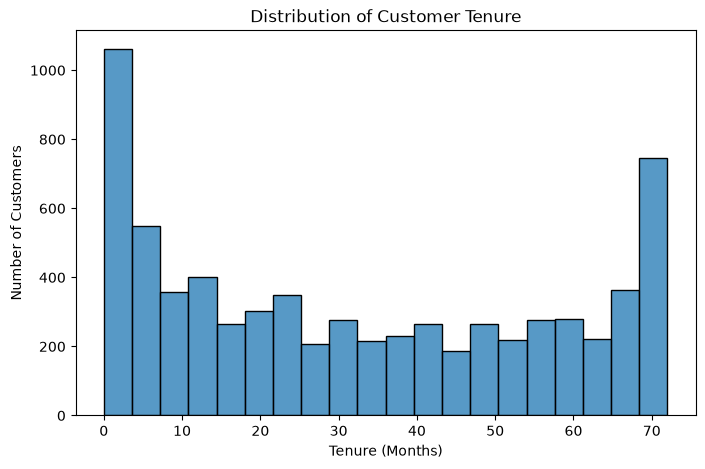

In [9]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="Tenure Months",
    bins=20
)

plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

Observations

- The tenure distribution is not uniform.
- A large number of customers have very low tenure.
- Another large group of customers has very high tenure.
- The distribution appears to be bimodal, indicating two prominent groups of customers.
- Based on this plot alone, we cannot conclude whether low-tenure customers churn more            frequently. This requires further analysis with the target variable.

Boxplot

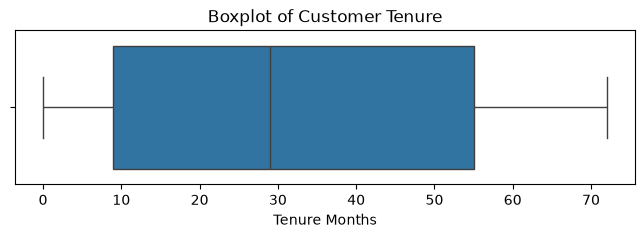

In [10]:
plt.figure(figsize=(8,2))

sns.boxplot(
    x=df["Tenure Months"]
)

plt.title("Boxplot of Customer Tenure")

plt.show()

Observations

- The average customer tenure is approximately **32 months**.
- Customer tenure ranges from **0 to 72 months**.
- The median tenure is **29 months**, indicating that half of the customers have stayed for less than 29 months.
- The distribution shows considerable variability (Standard Deviation ≈ 24.6 months).
- No outliers were detected based on the boxplot and the IQR rule.
- Together with the histogram, the data suggests that the company has many new customers as well as many long-term customers.

2. Monthly Charges

In [11]:
df["Monthly Charges"].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: Monthly Charges, dtype: float64

Histogram

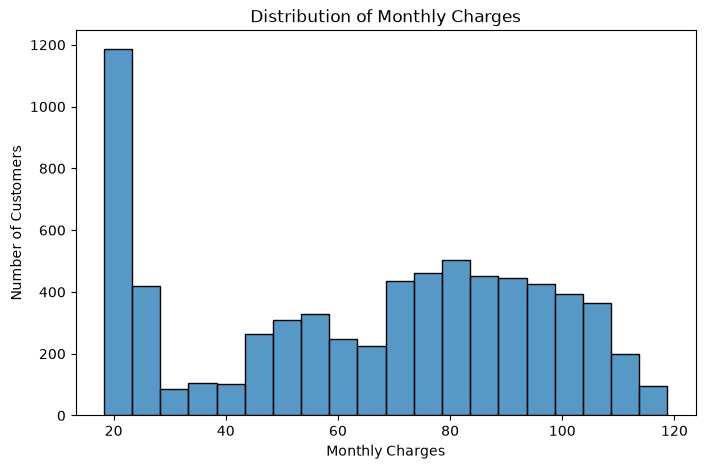

In [12]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="Monthly Charges",
    bins=20
)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

Boxplot

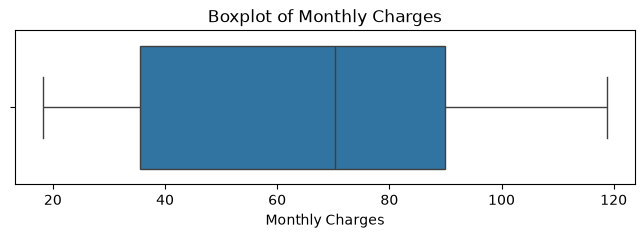

In [13]:
plt.figure(figsize=(8,2))

sns.boxplot(x=df["Monthly Charges"])

plt.title("Boxplot of Monthly Charges")

plt.show()

Observations

- The average monthly charge is approximately **64.76**.
- Monthly charges range from **18.25 to 118.75**.
- The median monthly charge (**70.35**) is slightly higher than the mean, suggesting a slight left skew.
- The histogram appears **bimodal**, indicating two groups of customers with different billing levels.
- No significant outliers were detected based on the boxplot and IQR rule.
- The wide range of monthly charges suggests customers subscribe to different service plans or bundles.

3. Total Chargers

In [14]:
df["Total Charges"].describe() # Total Charges column is been treated as object instead of numeric

count     7043.0
unique    6531.0
top         20.2
freq        11.0
Name: Total Charges, dtype: float64

In [15]:
# This code shows the Total Charges values that cannot be converted to numerical values.

df["Total Charges"].loc[
    pd.to_numeric(df["Total Charges"], errors="coerce").isna()
]

2234     
2438     
2568     
2667     
2856     
4331     
4687     
5104     
5719     
6772     
6840     
Name: Total Charges, dtype: object

In [16]:


df.loc[
    pd.to_numeric(df["Total Charges"], errors="coerce").isna(),
    ["CustomerID", "Tenure Months", "Monthly Charges", "Total Charges"]
]

,CustomerID,Tenure Months,Monthly Charges,Total Charges
2234,4472-LVYGI,0,52.55,
2438,3115-CZMZD,0,20.25,
2568,5709-LVOEQ,0,80.85,
2667,4367-NUYAO,0,25.75,
2856,1371-DWPAZ,0,56.05,
4331,7644-OMVMY,0,19.85,
4687,3213-VVOLG,0,25.35,
5104,2520-SGTTA,0,20.00,
5719,2923-ARZLG,0,19.70,
6772,4075-WKNIU,0,73.35,


Because these customers have 0 months of tenure, so their accumulated total charge is appropriately treated as 0 for this dataset.

In [17]:
# We'll convert Total Charges to numeric:
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"],
    errors="coerce"
)
# The blank values will become NaN.

In [18]:
# The blank values will become NaN.
df["Total Charges"] = df["Total Charges"].fillna(0)

In [19]:
df["Total Charges"].dtype
df["Total Charges"].isna().sum()

np.int64(0)

In [20]:
df["Total Charges"].describe()

count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: Total Charges, dtype: float64

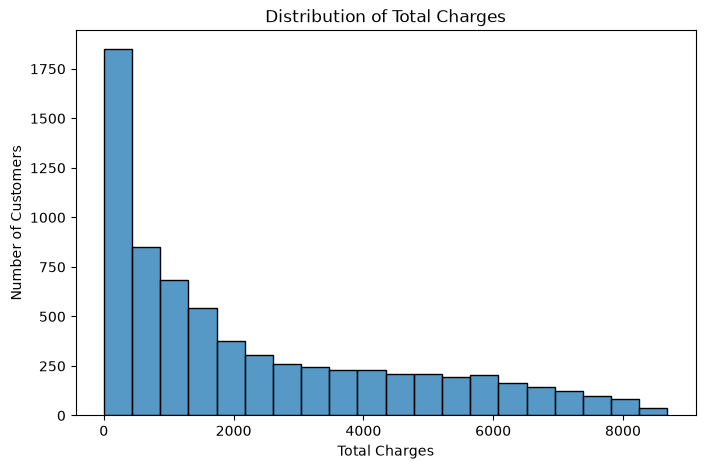

In [21]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="Total Charges",
    bins=20
)

plt.title("Distribution of Total Charges")
plt.xlabel("Total Charges")
plt.ylabel("Number of Customers")

plt.show()

Observations

- Total Charges is strongly right-skewed.
- A large proportion of customers have relatively low total charges.
- The number of customers decreases as total charges increase, producing a long right tail.
- The mean (2279.73) is substantially higher than the median (1394.55), supporting the presence of positive skewness.
- Total charges are expected to be strongly related to customer tenure, since customers who stay longer have more time to accumulate charges.

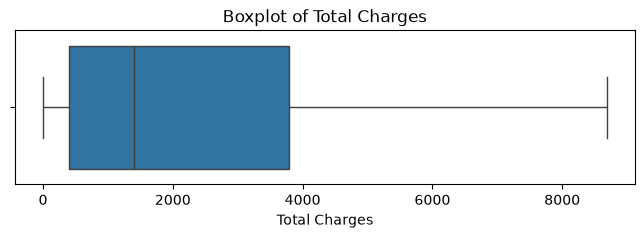

In [22]:
plt.figure(figsize=(8,2))

sns.boxplot(x=df["Total Charges"])

plt.title("Boxplot of Total Charges")

plt.show()

Observations

- Total Charges is strongly right-skewed.
- The median total charge is approximately 1394.55.
- There is substantial variability in total charges.
- The long right whisker is consistent with the positive skewness observed in the histogram.
- No observations were identified as outliers using the boxplot's IQR rule.
- Total Charges is likely strongly related to Tenure Months, since longer-tenured customers have more time to accumulate charges.

In [23]:
df["CLTV"].describe()

count    7043.000000
mean     4400.295755
std      1183.057152
min      2003.000000
25%      3469.000000
50%      4527.000000
75%      5380.500000
max      6500.000000
Name: CLTV, dtype: float64

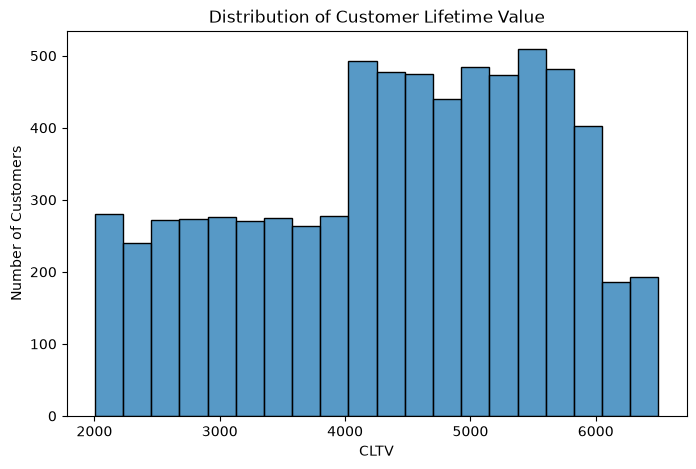

In [24]:
plt.figure(figsize=(8,5))

sns.histplot(
    data = df,
    x = 'CLTV',
    bins = 20
)

plt.title("Distribution of Customer Lifetime Value")
plt.xlabel("CLTV")
plt.ylabel("Number of Customers")

plt.show()

CLTV appears to have an irregular distribution, with a larger concentration
of customers between approximately 4,100 and 6,000. The distribution does
not appear strongly normally distributed.

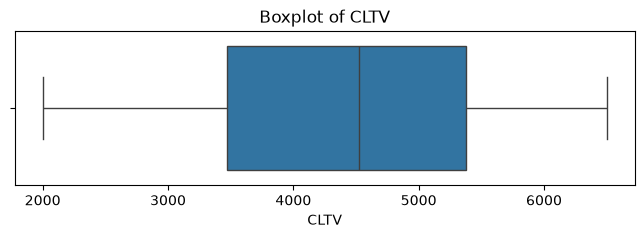

In [25]:
plt.figure(figsize=(8,2))
sns.boxplot(x=df["CLTV"])
plt.title("Boxplot of CLTV")
plt.show()

## Phase 3.2 : Bivariate Analysis

Tenure vs Churn

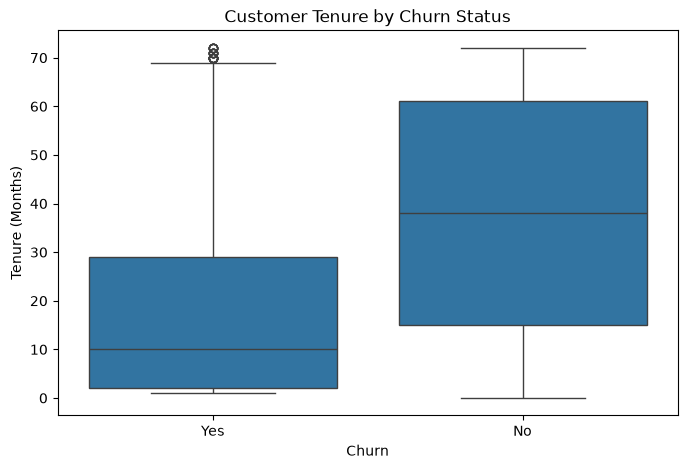

In [26]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Churn Label",
    y="Tenure Months"
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

Customers who churned generally have much shorter tenure than customers
who stayed. The median tenure is approximately 10 months for churned
customers compared with approximately 38 months for customers who stayed.

This suggests that newer customers are more likely to churn.

Monthly Charges vs Churn

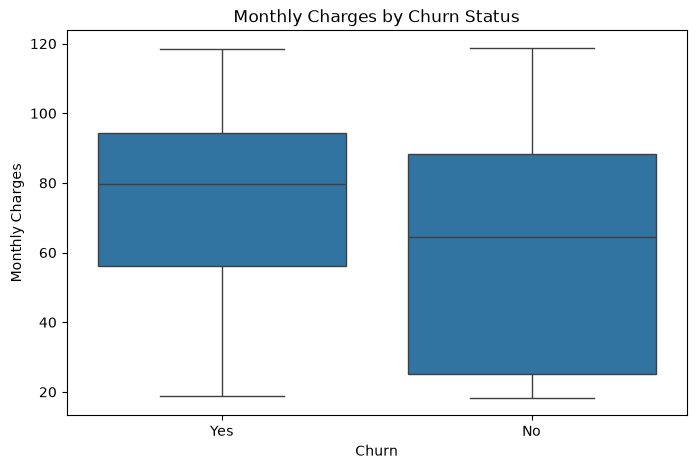

In [27]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Churn Label",
    y="Monthly Charges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

Churned customers have a higher median monthly charge (approximately 80)
than customers who stayed (approximately 65).

This suggests that higher monthly charges are associated with a greater
likelihood of churn. However, the distributions overlap substantially,
so Monthly Charges alone cannot explain churn.

Total Charges vs Churn

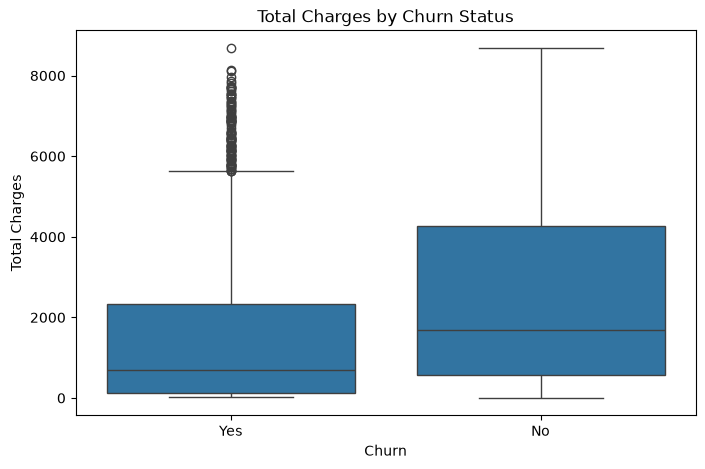

In [28]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Churn Label",
    y="Total Charges"
)

plt.title("Total Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Total Charges")

plt.show()

Churned customers generally have lower Total Charges than customers who
stayed. The median Total Charges is substantially lower for churned
customers.

This is likely related to the shorter tenure observed among churned
customers, since customers who stay longer have more time to accumulate
charges.

Therefore, Total Charges shows an association with churn, but its
relationship with Tenure should also be considered.

CLTV vs Churn

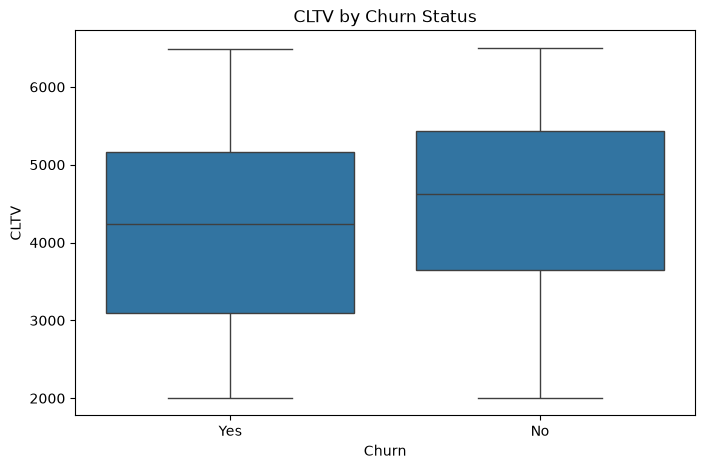

In [29]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data = df,
    x = "Churn Label",
    y = "CLTV"
)

plt.title("CLTV by Churn Status")
plt.xlabel("Churn")
plt.ylabel("CLTV")

plt.show()

Customers who stayed have a slightly higher median CLTV than customers
who churned. However, the distributions overlap considerably, suggesting
that CLTV alone does not strongly distinguish between churned and retained
customers.

Contract Type vs Churn

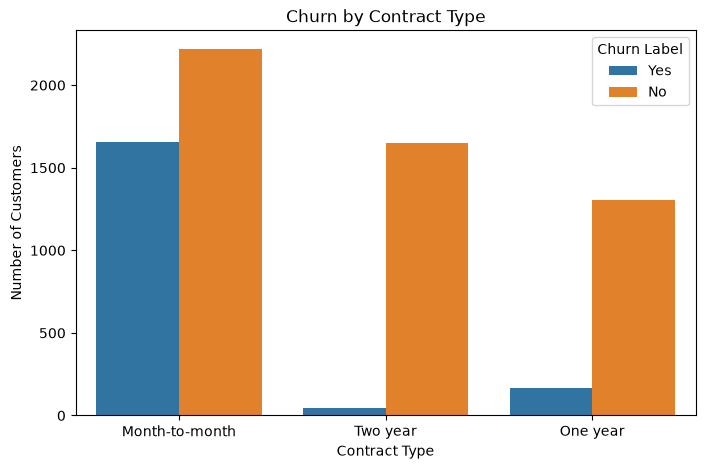

In [30]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn Label"
)

plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

The count plot shows a strong relationship between contract type and churn.
Month-to-month customers account for most churned customers, while very
few customers with one-year and two-year contracts churn.

Because the number of customers differs across contract types, churn
rates should be calculated within each contract category for a fair
comparison.

In [31]:
pd.crosstab(  # crosstab creates a frequency table showing how two categorical variables are related.
    df["Contract"],
    df["Churn Label"],
    normalize="index"
) * 100

Churn Label,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


Contract type shows a strong association with customer churn. The observed
churn rate is 42.71% for month-to-month customers, 11.27% for one-year
customers, and only 2.83% for two-year customers.

Therefore, customers with longer-term contracts have substantially lower
observed churn rates than month-to-month customers.

Internet Service vs Churn

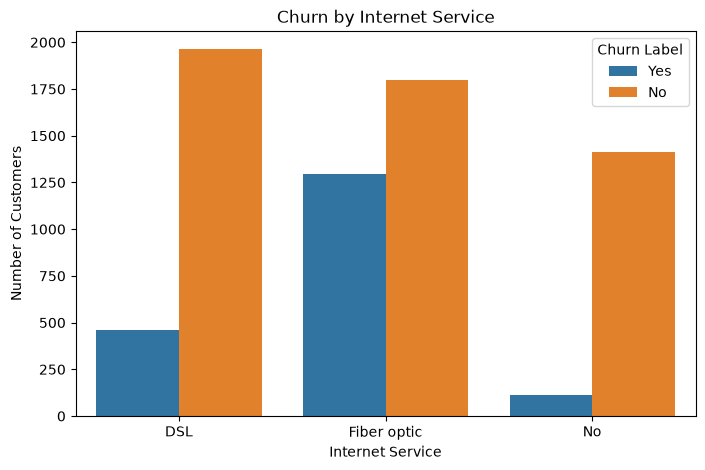

In [32]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Internet Service",
    hue="Churn Label"
)

plt.title("Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

In [33]:
pd.crosstab(
    df["Internet Service"],
    df["Churn Label"],
    normalize="index"
) * 100

Churn Label,No,Yes
Internet Service,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


Internet Service vs Churn:

Internet Service shows a strong association with customer churn. The
observed churn rate is 41.89% for fiber-optic customers, 18.96% for DSL
customers, and 7.40% for customers without internet service.

Fiber-optic customers therefore have the highest observed churn rate among
the three groups.

Payment Method vs Churn

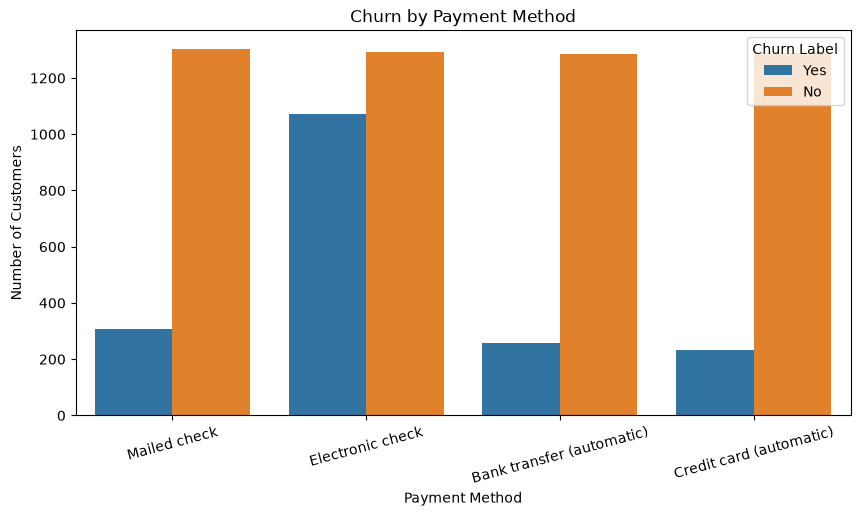

In [34]:
plt.figure(figsize=(10,5))

sns.countplot(
    data = df,
    x = "Payment Method",
    hue = "Churn Label"
)

plt.title("Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)

plt.show()

In [35]:
pd.crosstab(
    df["Payment Method"],
    df["Churn Label"],
    normalize="index"
) * 100

Churn Label,No,Yes
Payment Method,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


Electronic check customers have the highest observed churn rate (45.29%).
The churn rates for mailed check, automatic bank transfer, and automatic
credit card customers are considerably lower (15–19%).

Therefore, payment method shows a strong association with customer churn.

Pattern so far
We now have:
Month-to-month contract → 42.71% churn

Fiber optic → 41.89% churn

Electronic check → 45.29% churn

Short tenure → much higher churn

Higher monthly charges → higher churn

Tech Support vs Churn

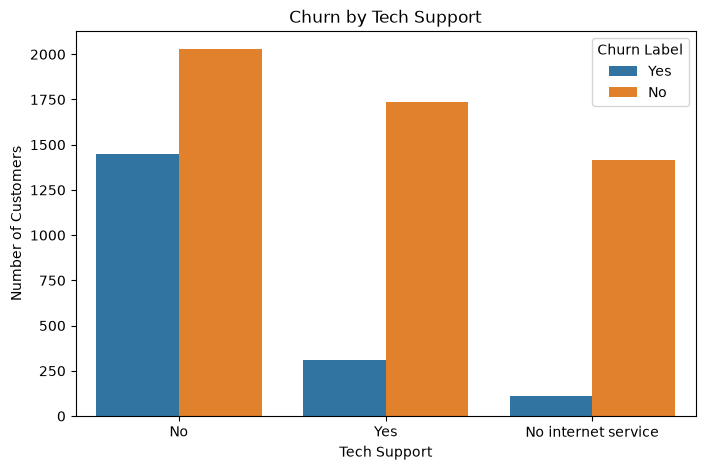

In [36]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Tech Support",
    hue="Churn Label"
)

plt.title("Churn by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Number of Customers")

plt.show()

In [37]:
pd.crosstab(df["Tech Support"],
            df["Churn Label"],
            normalize="index") * 100

Churn Label,No,Yes
Tech Support,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


Customers without Tech Support have a much higher observed churn rate
(41.64%) compared with customers who have Tech Support (15.17%).

Customers with no internet service have the lowest churn rate (7.40%).

Therefore, Tech Support shows a strong association with customer churn.

We're repeatedly seeing ~40%+ churn among certain groups:

Month-to-month → 42.71%, 
Fiber optic → 41.89%, 
Electronic check → 45.29%, 
No Tech Support → 41.64%, 

That's exactly the kind of pattern EDA is supposed to uncover.

Online Security vs Churn

<function matplotlib.pyplot.show(close=None, block=None)>

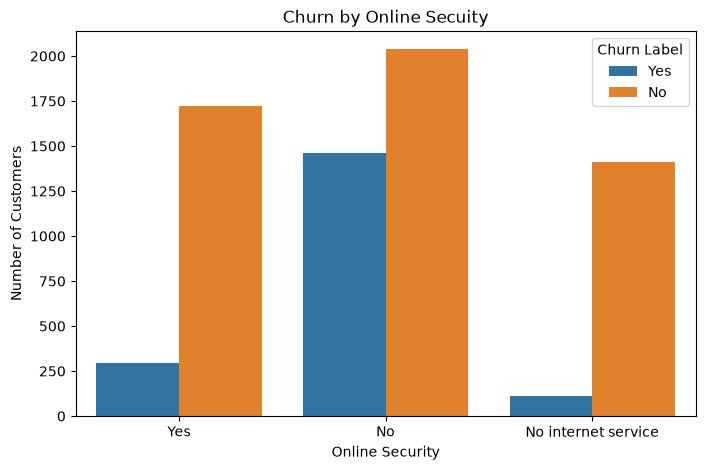

In [39]:
plt.figure(figsize=(8,5))

sns.countplot(
    data = df,
    x = "Online Security",
    hue = "Churn Label",
)

plt.title("Churn by Online Secuity")
plt.xlabel("Online Security")
plt.ylabel("Number of Customers")

plt.show

In [40]:
pd.crosstab(
    df["Online Security"],
    df["Churn Label"],
    normalize="index"
) * 100

Churn Label,No,Yes
Online Security,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


Customers without Online Security have a much higher observed churn rate
(41.77%) compared with customers who have Online Security (14.61%).

Customers with no internet service have the lowest churn rate (7.40%).

Therefore, Online Security shows a strong association with customer churn.

Online Backup vs Churn

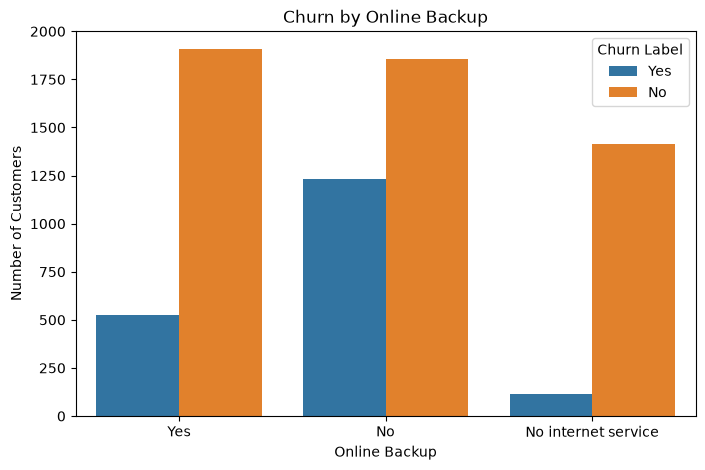

In [41]:
plt.figure(figsize=(8,5))

sns.countplot(
    data =df,
    x = "Online Backup",
    hue = "Churn Label"
)

plt.title("Churn by Online Backup")
plt.xlabel("Online Backup")
plt.ylabel("Number of Customers")

plt.show()

In [44]:
pd.crosstab(
    df["Online Backup"],
    df["Churn Label"],
    normalize="index"
) * 100

Churn Label,No,Yes
Online Backup,,
No,60.071244,39.928756
No internet service,92.595020,7.404980
Yes,78.468506,21.531494


Customers without Online Backup have a higher observed churn rate (39.93%)
than customers with Online Backup (21.53%).

Customers with no internet service have the lowest churn rate (7.40%).

Therefore, Online Backup shows an association with customer churn.

Device Protection vs Churn

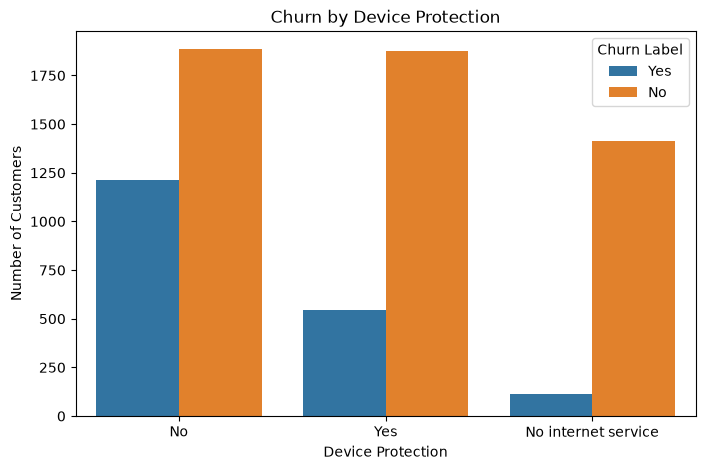

In [53]:
plt.figure(figsize=(8,5))

sns.countplot(
    data =df,
    x = "Device Protection",
    hue = "Churn Label"
)

plt.title("Churn by Device Protection")
plt.xlabel("Device Protection")
plt.ylabel("Number of Customers")

plt.show()

In [46]:
pd.crosstab(
    df["Device Protection"],
    df["Churn Label"],
    normalize="index"
) * 100

Churn Label,No,Yes
Device Protection,,
No,60.872375,39.127625
No internet service,92.595020,7.404980
Yes,77.497936,22.502064


Customers without Device Protection have a higher observed churn rate
(39.13%) than customers with Device Protection (22.50%).

Customers with no internet service have the lowest churn rate (7.40%).

Therefore, Device Protection shows an association with customer churn.

Streaming TV vs Churn

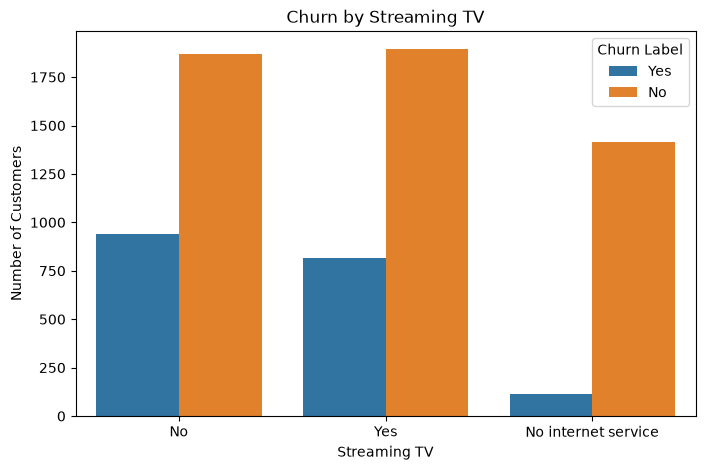

In [47]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Streaming TV",
    hue="Churn Label"
)

plt.title("Churn by Streaming TV")
plt.xlabel("Streaming TV")
plt.ylabel("Number of Customers")

plt.show()

In [48]:
pd.crosstab(
    df["Streaming TV"],
    df["Churn Label"],
    normalize="index"
) * 100

Churn Label,No,Yes
Streaming TV,,
No,66.476868,33.523132
No internet service,92.595020,7.404980
Yes,69.929812,30.070188


Customers without Streaming TV have an observed churn rate of 33.52%,
while customers with Streaming TV have a churn rate of 30.07%.

The difference is relatively small, suggesting that Streaming TV has a
weaker association with churn compared with variables such as Contract
Type, Payment Method, Tech Support, and Online Security.

Customers with no internet service have a much lower churn rate of 7.40%.

Streaming Movies vs Churn

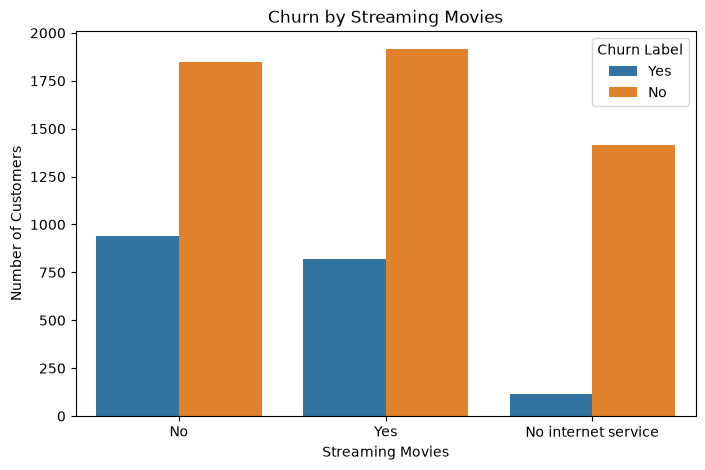

In [49]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Streaming Movies",
    hue="Churn Label"
)

plt.title("Churn by Streaming Movies")
plt.xlabel("Streaming Movies")
plt.ylabel("Number of Customers")

plt.show()

In [50]:
pd.crosstab(
    df["Streaming Movies"],
    df["Churn Label"],
    normalize="index"
) * 100

Churn Label,No,Yes
Streaming Movies,,
No,66.319569,33.680431
No internet service,92.595020,7.404980
Yes,70.058565,29.941435


The difference is only about 3.7 percentage points, so this appears to be a relatively weak association with churn.

Streaming Movies does not appear to be a strong standalone predictor of churn based on this analysis.

Paperless Billing vs Churn

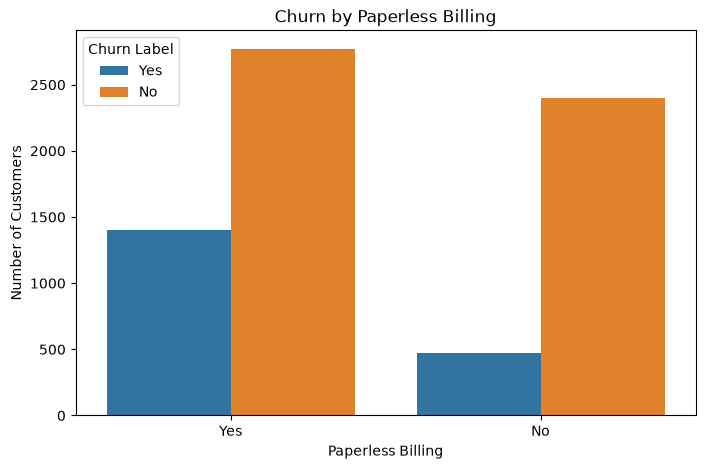

In [51]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Paperless Billing",
    hue="Churn Label"
)

plt.title("Churn by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Number of Customers")

plt.show()

In [52]:
pd.crosstab(
    df["Paperless Billing"],
    df["Churn Label"],
    normalize="index"
) * 100

Churn Label,No,Yes
Paperless Billing,,
No,83.669916,16.330084
Yes,66.434908,33.565092


Customers with paperless billing have a higher observed churn rate (33.57%)
than customers without paperless billing (16.33%).

Therefore, Paperless Billing shows a noticeable association with customer churn.

Senior Citizen vs Churn

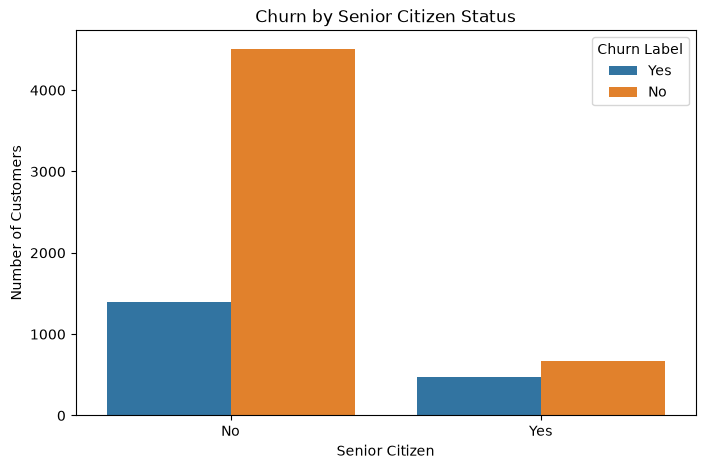

In [54]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Senior Citizen",
    hue="Churn Label"
)

plt.title("Churn by Senior Citizen Status")
plt.xlabel("Senior Citizen")
plt.ylabel("Number of Customers")

plt.show()

In [55]:
pd.crosstab(
    df["Senior Citizen"],
    df["Churn Label"],
    normalize="index"
) * 100

Churn Label,No,Yes
Senior Citizen,,
No,76.393832,23.606168
Yes,58.318739,41.681261


Senior citizens have a higher observed churn rate (41.68%) compared
with non-senior citizens (23.61%).

Therefore, Senior Citizen shows a noticeable association with customer churn.

Dependents vs Churn.

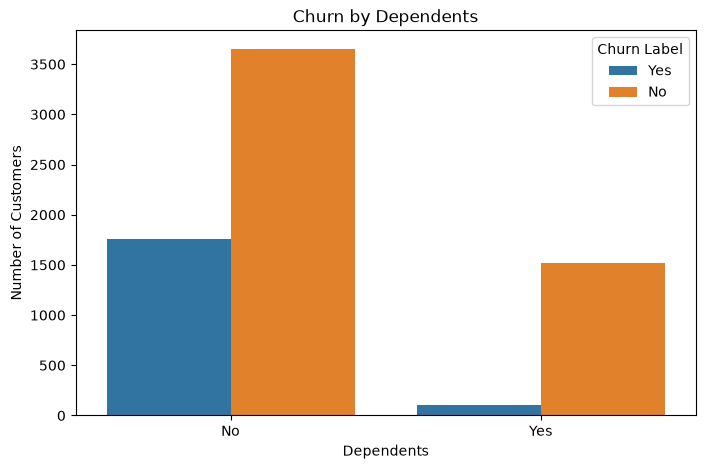

In [56]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Dependents",
    hue="Churn Label"
)

plt.title("Churn by Dependents")
plt.xlabel("Dependents")
plt.ylabel("Number of Customers")

plt.show()

In [57]:
pd.crosstab(
    df["Dependents"],
    df["Churn Label"],
    normalize="index"
) * 100

Churn Label,No,Yes
Dependents,,
No,67.448301,32.551699
Yes,93.484942,6.515058


Customers without dependents have a much higher observed churn rate
(32.55%) compared with customers with dependents (6.52%).

Therefore, Dependents shows a strong association with customer churn.

Partner vs Churn

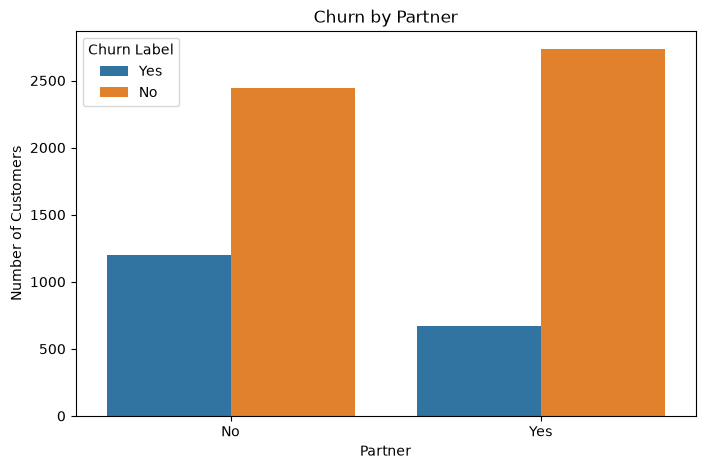

In [58]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Partner",
    hue="Churn Label"
)

plt.title("Churn by Partner")
plt.xlabel("Partner")
plt.ylabel("Number of Customers")

plt.show()

In [59]:
pd.crosstab(
    df["Partner"],
    df["Churn Label"],
    normalize="index"
) * 100

Churn Label,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903


Customers without a partner have a higher observed churn rate (32.96%)
than customers with a partner (19.66%).

Therefore, Partner shows a moderate association with customer churn.

Multi Lines vs Churn

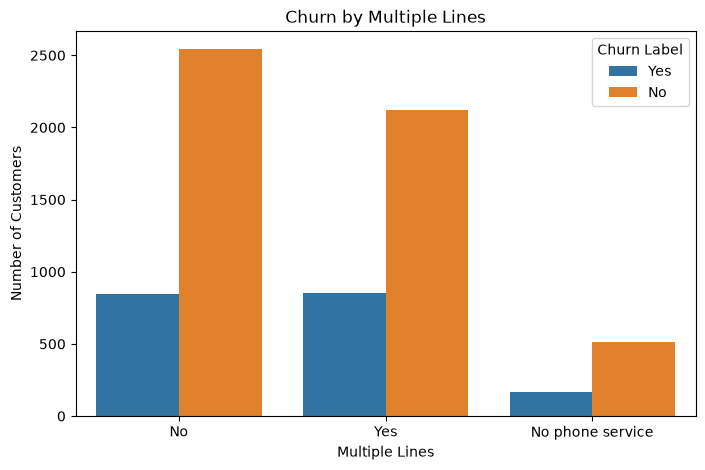

In [60]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Multiple Lines",
    hue="Churn Label"
)

plt.title("Churn by Multiple Lines")
plt.xlabel("Multiple Lines")
plt.ylabel("Number of Customers")

plt.show()

In [61]:
pd.crosstab(
    df["Multiple Lines"],
    df["Churn Label"],
    normalize="index"
) * 100

Churn Label,No,Yes
Multiple Lines,,
No,74.955752,25.044248
No phone service,75.073314,24.926686
Yes,71.390104,28.609896


Multiple Lines appears to have a weak association with churn.

## Exploratory Data Analysis (EDA) — Churn Prediction
1. Target Variable — Churn

The target variable Churn Label contains two classes:

No Churn: 73.46%
Churn: 26.54%

This indicates a moderate class imbalance. Therefore, accuracy alone may not be sufficient for evaluating the machine learning model. Metrics such as precision, recall, F1-score, and the confusion matrix will also be considered.

2. Numerical Variables

We examined the distributions of Tenure, Monthly Charges, Total Charges, and CLTV using histograms and boxplots.

Tenure

Mean = 32.37 months
Median = 29 months
Range = 0–72 months
Customers are concentrated at lower tenure values.

Monthly Charges

Mean = 64.76
Median = 70.35
Range = 18.25–118.75
The distribution is spread across a wide range of monthly charges.

Total Charges

Mean = 2279.73
Median = 1394.55
Range = 0–8684.80
The distribution is strongly right-skewed, with many customers having relatively low total charges.

CLTV

Mean = 4400.30
Median = 4527
Range = 2003–6500
The distribution is relatively well spread without obvious extreme outliers.

3. Total Charges Data Issue

The Total Charges column was initially stored as object instead of a numerical data type.

After converting it to numeric, 11 missing values were identified.

These customers had:

Tenure = 0 months

This explains why their Total Charges were blank: they were new customers who had not accumulated any charges yet.

This issue will be handled during data preprocessing.


4. Categorical Variables vs Churn

We compared the churn rate across different categories.

Stronger associations with churn
Month-to-month contract: 42.71% churn
Electronic check: 45.29% churn
Fiber optic internet: 41.89% churn
No Tech Support: 41.64% churn
No Online Security: 41.77% churn
Senior Citizens: 41.68% churn
Paperless Billing: 33.57% churn
No Dependents: 32.55% churn

These variables showed noticeable differences in churn rates between their categories.

Weaker associations
Streaming TV
Streaming Movies
Multiple Lines

For these variables, the difference in churn rates between categories was relatively small.


5. Important EDA Conclusion

EDA helped us identify patterns and potential relationships between customer characteristics and churn.

However:

Association does not mean causation.

A variable showing a high churn rate in one category does not necessarily mean that the variable causes customers to churn.

Also, a variable that appears weak during individual analysis should not automatically be removed, because it may become useful when combined with other variables in a machine learning model.
